In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("../Dataset/data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0


In [6]:
df.tail()

,Duration,Date,Pulse,Maxpulse,Calories
27,60,'2020/12/27',92,118,241.0
28,60,'2020/12/28',103,132,NaN
29,60,'2020/12/29',100,132,280.0
30,60,'2020/12/30',102,129,380.3
31,60,'2020/12/31',92,115,243.0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB


In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 32
Columns: 5


In [9]:
df.describe()

,Duration,Pulse,Maxpulse,Calories
count,32.000000,32.000000,32.000000,30.000000
mean,68.437500,103.500000,128.500000,304.680000
std,70.039591,7.832933,12.998759,66.003779
min,30.000000,90.000000,101.000000,195.100000
25%,60.000000,100.000000,120.000000,250.700000
50%,60.000000,102.500000,127.500000,291.200000
75%,60.000000,106.500000,132.250000,343.975000
max,450.000000,130.000000,175.000000,479.000000


In [10]:
print(df.columns)

Index(['Duration', 'Date', 'Pulse', 'Maxpulse', 'Calories'], dtype='object')


In [11]:
df.isnull().sum()

Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Duration    0.000
Date        3.125
Pulse       0.000
Maxpulse    0.000
Calories    6.250
dtype: float64


In [13]:
df["Date"] = df["Date"].astype("string").str.strip().str.strip("'\"")

df["Date"] = df["Date"].replace({
    "20201226": "2020-12-26"
})

df["Date"] = pd.to_datetime(
    df["Date"],
    format="mixed",
    errors="coerce"
)

df.loc[df["Date"].isnull(), "Date"] = pd.Timestamp("2020-12-22")

In [14]:
df.loc[df["Duration"] == 450, "Duration"] = 45

In [15]:
for duration, idx in df[df["Calories"].isnull()].groupby("Duration").groups.items():

    median_value = df.loc[
        (df["Duration"] == duration) &
        (df["Calories"].notnull()),
        "Calories"
    ].median()

    if pd.isna(median_value):
        median_value = df["Calories"].median()

    df.loc[list(idx), "Calories"] = median_value

In [16]:

print("Duplicate records:", df.duplicated().sum())

Duplicate records: 1


In [17]:
df = df.drop_duplicates()

In [18]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Duration    0
Date        0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64

Duplicate Records:
0


In [19]:
duration_data = df[df["Duration"] >= 45]

display(duration_data)

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.10
1,60,2020-12-02,117,145,479.00
2,60,2020-12-03,103,135,340.00
3,45,2020-12-04,109,175,282.40
4,45,2020-12-05,117,148,406.00
5,60,2020-12-06,102,127,300.00
6,60,2020-12-07,110,136,374.00
7,45,2020-12-08,104,134,253.30
9,60,2020-12-10,98,124,269.00
10,60,2020-12-11,103,147,329.30


In [20]:
calories_data = df[df["Calories"] >= 250]

display(calories_data)

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.10
1,60,2020-12-02,117,145,479.00
2,60,2020-12-03,103,135,340.00
3,45,2020-12-04,109,175,282.40
4,45,2020-12-05,117,148,406.00
5,60,2020-12-06,102,127,300.00
6,60,2020-12-07,110,136,374.00
7,45,2020-12-08,104,134,253.30
9,60,2020-12-10,98,124,269.00
10,60,2020-12-11,103,147,329.30


In [21]:
filtered_data = df[
    (df["Duration"] >= 45) &
    (df["Calories"] >= 250)
]

display(filtered_data)

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.10
1,60,2020-12-02,117,145,479.00
2,60,2020-12-03,103,135,340.00
3,45,2020-12-04,109,175,282.40
4,45,2020-12-05,117,148,406.00
5,60,2020-12-06,102,127,300.00
6,60,2020-12-07,110,136,374.00
7,45,2020-12-08,104,134,253.30
9,60,2020-12-10,98,124,269.00
10,60,2020-12-11,103,147,329.30


In [22]:
filtered_data.to_csv(
    "../Output/Filtered_Workout_Data.csv",
    index=False
)

In [23]:
df["Calories_Per_Minute"] = (
    df["Calories"] / df["Duration"]
).round(2)

In [24]:
df["Heart_Rate_Difference"] = (
    df["Maxpulse"] - df["Pulse"]
)

In [25]:
df["Workout_Intensity"] = pd.cut(
    df["Pulse"],
    bins=[-np.inf, 100, 110, np.inf],
    labels=["Low", "Moderate", "High"]
)

In [26]:
df["Heart_Rate_Check"] = np.where(
    df["Maxpulse"] >= df["Pulse"],
    "Valid",
    "Review"
)

In [27]:

df.head()

,Duration,Date,Pulse,Maxpulse,Calories,Calories_Per_Minute,Heart_Rate_Difference,Workout_Intensity,Heart_Rate_Check
0,60,2020-12-01,110,130,409.1,6.82,20,Moderate,Valid
1,60,2020-12-02,117,145,479.0,7.98,28,High,Valid
2,60,2020-12-03,103,135,340.0,5.67,32,Moderate,Valid
3,45,2020-12-04,109,175,282.4,6.28,66,Moderate,Valid
4,45,2020-12-05,117,148,406.0,9.02,31,High,Valid


In [28]:
import matplotlib.pyplot as plt

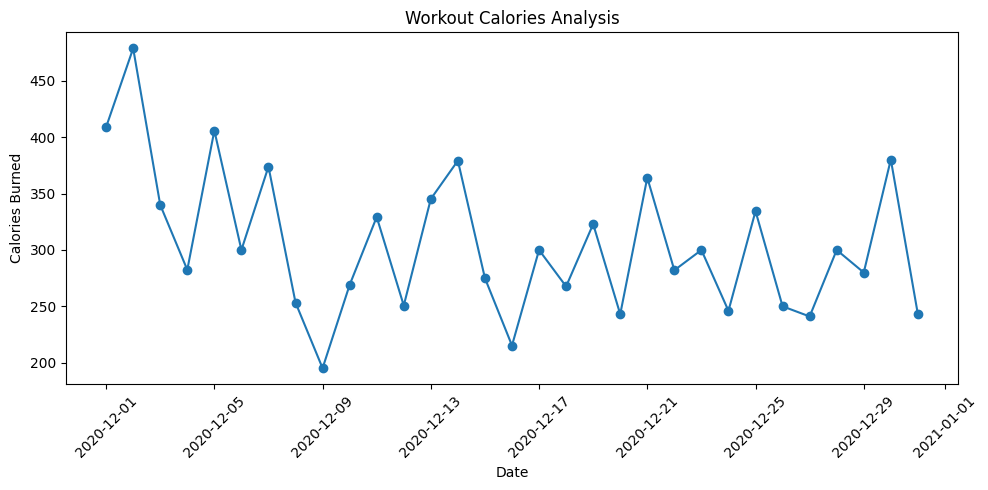

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["Date"],
    df["Calories"],
    marker="o"
)

plt.title("Workout Calories Analysis")

plt.xlabel("Date")
plt.ylabel("Calories Burned")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

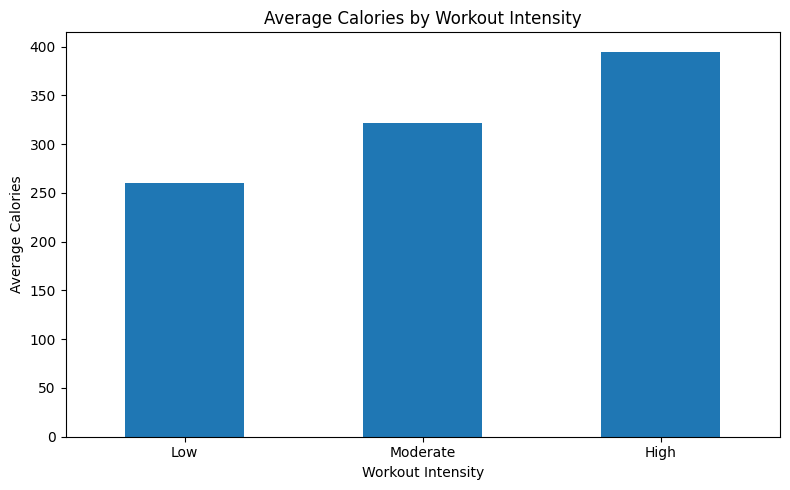

In [30]:
df.groupby(
    "Workout_Intensity",
    observed=False
)["Calories"].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Calories by Workout Intensity")
plt.xlabel("Workout Intensity")
plt.ylabel("Average Calories")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

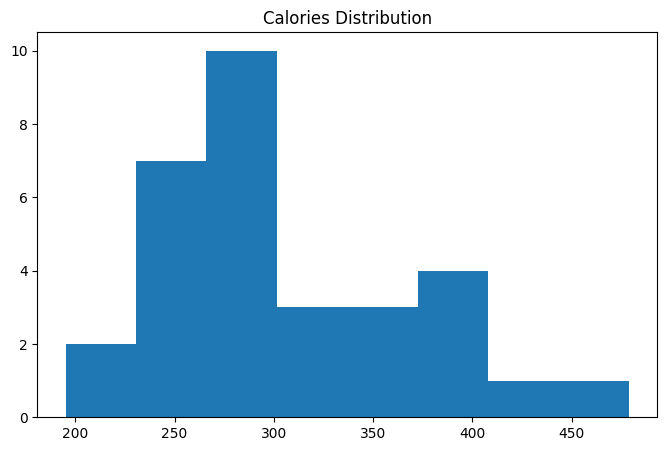

In [31]:
plt.figure(figsize=(8, 5))

plt.hist(df["Calories"], bins=8)

plt.title("Calories Distribution")

plt.savefig(
    "../Output/Calories_Distribution.png"
)

plt.show()

In [32]:
correlation = df[
    ["Duration", "Pulse", "Maxpulse", "Calories"]
].corr()

print(correlation)

          Duration     Pulse  Maxpulse  Calories
Duration  1.000000 -0.059452 -0.250033  0.366648
Pulse    -0.059452  1.000000  0.269672  0.511934
Maxpulse -0.250033  0.269672  1.000000  0.357268
Calories  0.366648  0.511934  0.357268  1.000000


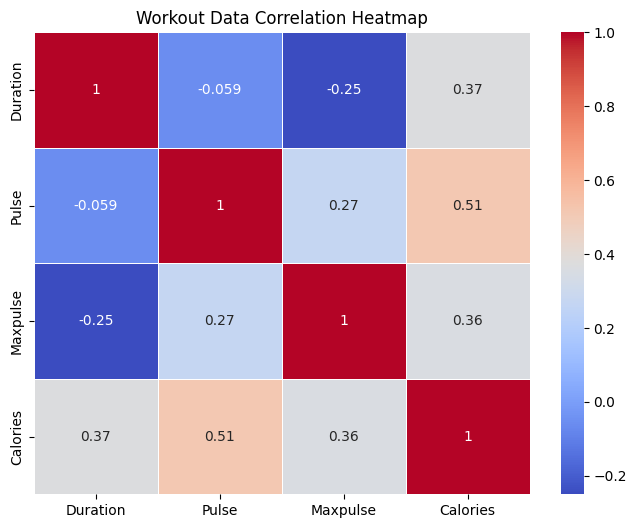

In [33]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Workout Data Correlation Heatmap")

plt.show()

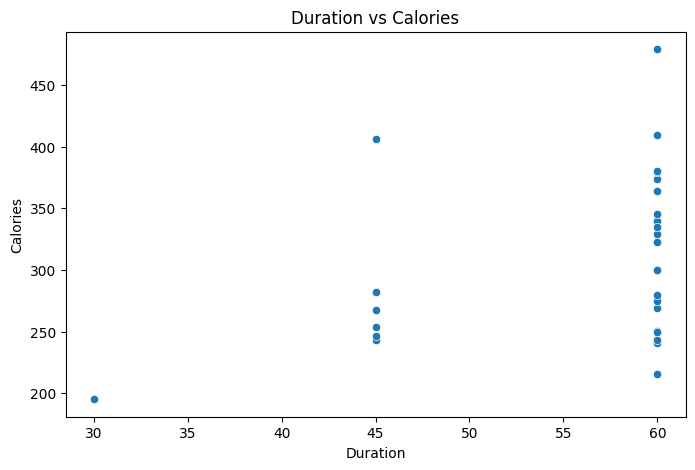

In [34]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Duration",
    y="Calories"
)

plt.title("Duration vs Calories")

plt.show()

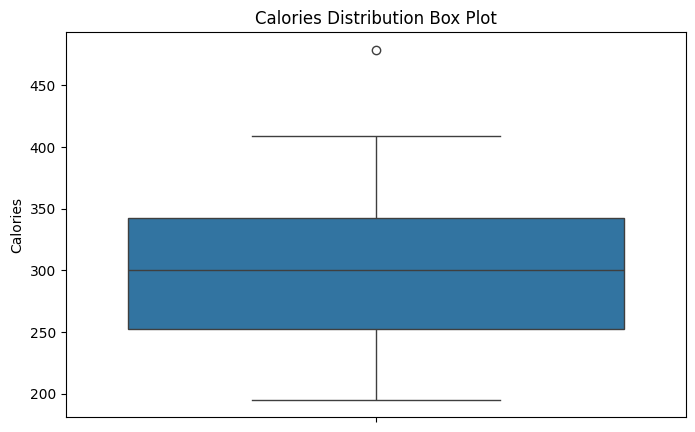

In [35]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    y="Calories"
)

plt.title("Calories Distribution Box Plot")

plt.show()

In [36]:
df.to_csv(
    "../Output/Cleaned_Workout_Data.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
